<a href="https://colab.research.google.com/github/rishabhucb/court-keypoints/blob/main/day4_homography_demo.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [20]:
!pip install -q ultralytics
from google.colab import drive
drive.mount('/content/drive')

import cv2, numpy as np, glob, os, random
import matplotlib.pyplot as plt
from ultralytics import YOLO

PROJECT_DIR = '/content/drive/MyDrive/court_keypoints'
TEST_IMGS = sorted(glob.glob(f'{PROJECT_DIR}/court_v4/test/images/*'))
FIG_DIR = f'{PROJECT_DIR}/figures'
os.makedirs(FIG_DIR, exist_ok=True)

kp_model = YOLO(f'{PROJECT_DIR}/runs/baseline_v4/weights/last.pt')   # your court model
person_model = YOLO('yolo11n.pt')                                    # standard model that detects people
print(len(TEST_IMGS), "test images")

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
11 test images


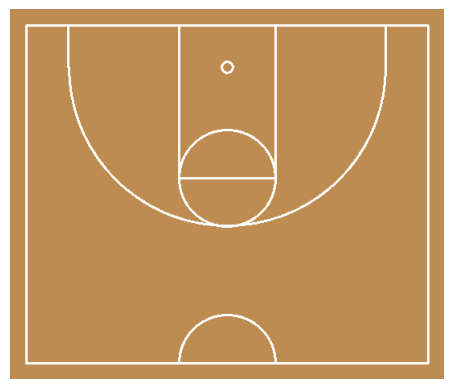

In [21]:
COURT_FT = {
    0: (0, 0),      1: (50, 0),      2: (0, 42),     12: (50, 42),   # corners / half-court sideline
    3: (19, 0),     4: (31, 0),      5: (31, 19),    6: (19, 19),    # paint (12 ft wide), FT line at 19 ft
    7: (5.25, 0),   8: (5.25, 5.25), 10: (44.75, 5.25), 11: (44.75, 0),  # 3-pt line ends
    9: (25, 25),                                                     # top of the arc (19'9" from hoop)
}
S, M = 10, 20                                   # 10 pixels per foot, 20 px margin
W, H = int(50*S + 2*M), int(42*S + 2*M)
P = lambda x, y: (int(M + x*S), int(M + y*S))
COURT_PX = {k: (M + x*S, M + y*S) for k, (x, y) in COURT_FT.items()}

def draw_court(img=None, color=(255, 255, 255)):
    if img is None:
        img = np.full((H, W, 3), (80, 140, 190), np.uint8)          # wood color
    cv2.rectangle(img, P(0, 0), P(50, 42), color, 2)                 # outline + half-court line
    cv2.rectangle(img, P(19, 0), P(31, 19), color, 2)                # paint
    cv2.circle(img, P(25, 19), 6*S, color, 2)                        # free-throw circle
    cv2.line(img, P(5.25, 0), P(5.25, 5.25), color, 2)               # corner-3 lines
    cv2.line(img, P(44.75, 0), P(44.75, 5.25), color, 2)
    cv2.ellipse(img, P(25, 5.25), (int(19.75*S),)*2, 0, 0, 180, color, 2)   # 3-pt arc
    cv2.circle(img, P(25, 5.25), int(0.75*S), color, 2)              # hoop
    cv2.ellipse(img, P(25, 42), (6*S, 6*S), 0, 180, 360, color, 2)   # center circle
    return img

plt.imshow(cv2.cvtColor(draw_court(), cv2.COLOR_BGR2RGB)); plt.axis('off'); plt.show()

In [22]:
for i in [7, 8, 9, 10, 11]:                       # use the measured 3-point positions
    COURT_FT[i] = measured[i][:2]
COURT_PX = {k: (M + x*S, M + y*S) for k, (x, y) in COURT_FT.items()}
USE_IDS = [3, 4, 5, 6, 7, 8, 9, 10, 11]           # skip the corner/sideline points
print({i: tuple(round(c, 1) for c in COURT_FT[i]) for i in USE_IDS})

{3: (19, 0), 4: (31, 0), 5: (31, 19), 6: (19, 19), 7: (6.8, 1.4), 8: (9.1, 16.8), 9: (24.5, 25.2), 10: (39.9, 19.7), 11: (47.7, 6.6)}


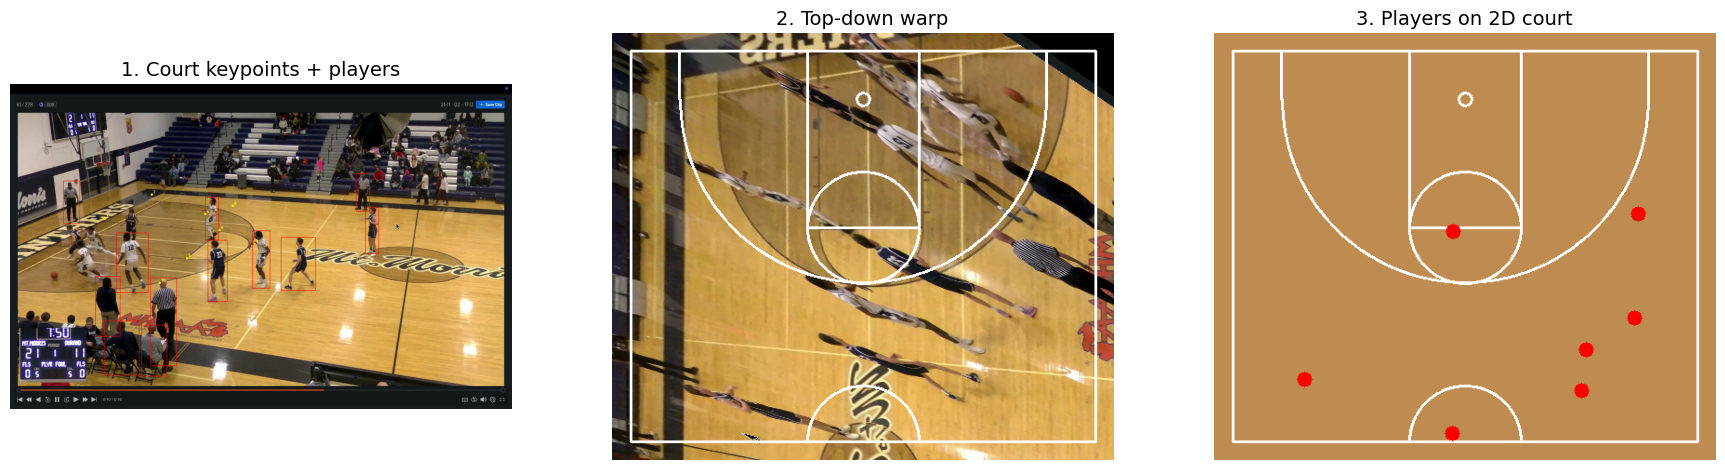

Used 8 keypoints: [3, 4, 5, 6, 7, 8, 9, 10]


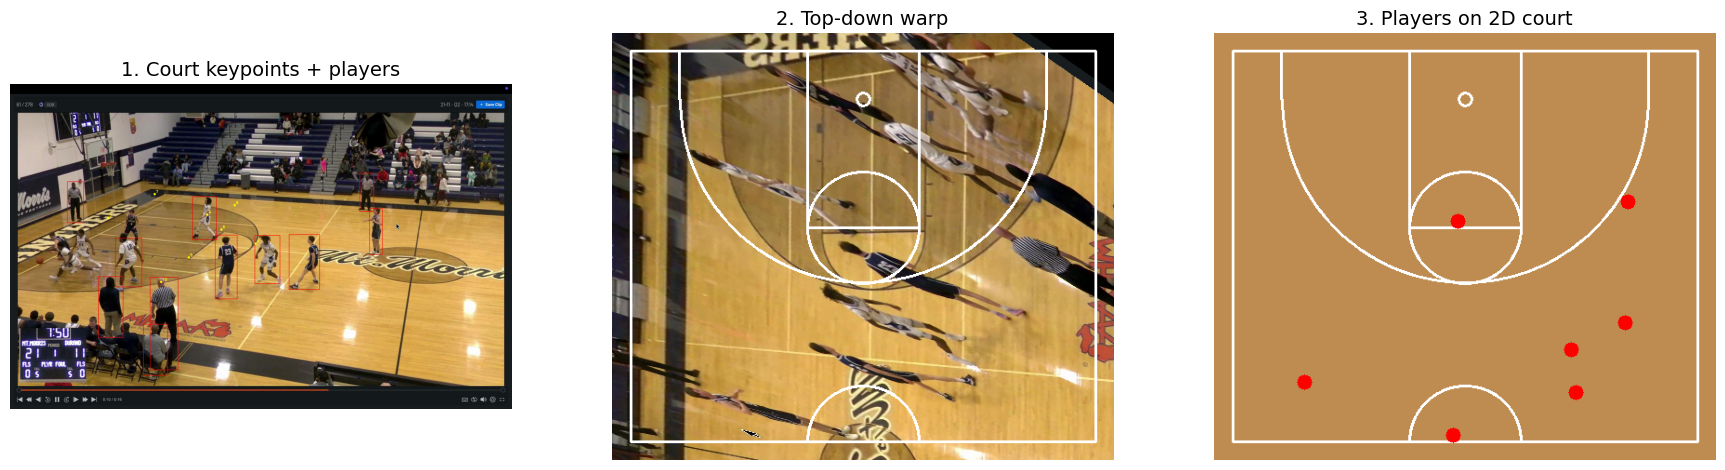

Used 8 keypoints: [3, 4, 5, 6, 7, 8, 9, 10]


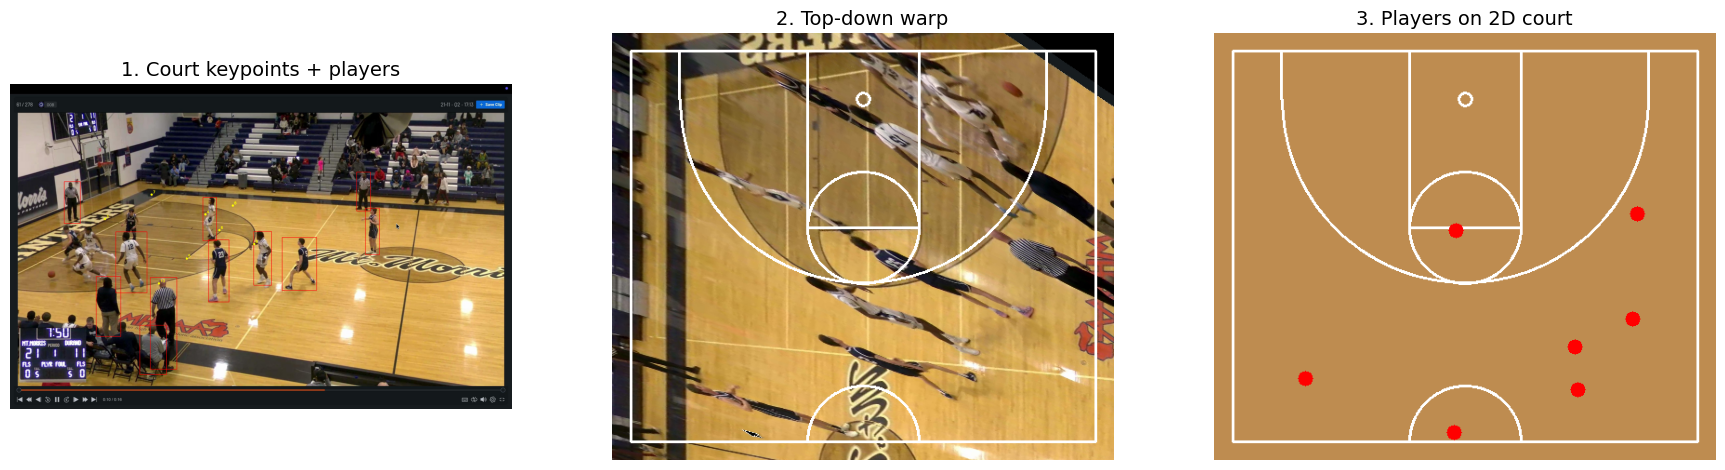

Used 8 keypoints: [3, 4, 5, 6, 7, 8, 9, 10]


In [23]:
def court_map(img_path, conf_th=0.5, name=None):
    img = cv2.imread(img_path)
    r = kp_model.predict(img, conf=0.25, verbose=False)[0]
    if r.keypoints is None or len(r.boxes) == 0:
        print("No court found"); return None
    best = int(r.boxes.conf.argmax())
    xy = r.keypoints.xy[best].cpu().numpy()
    kc = r.keypoints.conf[best].cpu().numpy()
    ids = [i for i in USE_IDS if kc[i] > conf_th]
    if len(ids) < 4:
        print("Only", len(ids), "confident points; need 4"); return None

    # Homography: image pixels -> court diagram pixels
    Hm, _ = cv2.findHomography(np.float32([xy[i] for i in ids]),
                               np.float32([COURT_PX[i] for i in ids]), cv2.RANSAC, 15.0)

    top = draw_court(cv2.warpPerspective(img, Hm, (W, H)))         # bird's-eye view

    # Players: feet = bottom-center of each person box
    boxes = person_model.predict(img, classes=[0], conf=0.4, verbose=False)[0].boxes.xyxy.cpu().numpy()
    court2d = draw_court()
    if len(boxes):
        feet = np.float32([[(b[0]+b[2])/2, b[3]] for b in boxes]).reshape(-1, 1, 2)
        for x, y in cv2.perspectiveTransform(feet, Hm).reshape(-1, 2):
            if 0 <= x < W and 0 <= y < H:
                cv2.circle(court2d, (int(x), int(y)), 8, (0, 0, 255), -1)

    vis = img.copy()
    for b in boxes:
        cv2.rectangle(vis, (int(b[0]), int(b[1])), (int(b[2]), int(b[3])), (0, 0, 255), 2)
    for i in ids:
        cv2.circle(vis, tuple(map(int, xy[i])), 7, (0, 255, 255), -1)
        cv2.putText(vis, str(i), (int(xy[i][0])+8, int(xy[i][1])-8), cv2.FONT_HERSHEY_SIMPLEX, 0.7, (0, 255, 255), 2)

    fig, ax = plt.subplots(1, 3, figsize=(22, 6))
    for a, im, t in zip(ax, [vis, top, court2d],
                        ['1. Court keypoints + players', '2. Top-down warp', '3. Players on 2D court']):
        a.imshow(cv2.cvtColor(im, cv2.COLOR_BGR2RGB)); a.set_title(t, fontsize=14); a.axis('off')
    if name:
        plt.savefig(f'{FIG_DIR}/{name}.png', bbox_inches='tight')
    plt.show()
    print(f"Used {len(ids)} keypoints: {ids}")
    return Hm

for k, p in enumerate(random.sample(TEST_IMGS, 3)):
    court_map(p, name=f'court_map_{k}')

In [24]:
def error_feet(img_path, Hm):
    h, w = cv2.imread(img_path).shape[:2]
    lbl = img_path.replace('/images/', '/labels/').rsplit('.', 1)[0] + '.txt'
    v = list(map(float, open(lbl).readline().split()))[5:]
    errs = []
    for i in USE_IDS:
        if v[3*i+2] > 0:
            p = cv2.perspectiveTransform(np.float32([[[v[3*i]*w, v[3*i+1]*h]]]), Hm)[0, 0]
            fx, fy = (p[0]-M)/S, (p[1]-M)/S
            errs.append(np.hypot(fx - COURT_FT[i][0], fy - COURT_FT[i][1]))
    return np.mean(errs) if errs else None

all_errs = []
for p in TEST_IMGS:
    Hm = court_map(p) if False else None   # (no plots here)
    img = cv2.imread(p)
    r = kp_model.predict(img, conf=0.25, verbose=False)[0]
    if r.keypoints is None or len(r.boxes) == 0: continue
    b = int(r.boxes.conf.argmax())
    xy, kc = r.keypoints.xy[b].cpu().numpy(), r.keypoints.conf[b].cpu().numpy()
    ids = [i for i in USE_IDS if kc[i] > 0.5]
    if len(ids) < 4: continue
    Hm, _ = cv2.findHomography(np.float32([xy[i] for i in ids]),
                               np.float32([COURT_PX[i] for i in ids]), cv2.RANSAC, 15.0)
    e = error_feet(p, Hm)
    if e is not None: all_errs.append(e)

print(f"Images evaluated: {len(all_errs)} / {len(TEST_IMGS)}")
print(f"Mean court-mapping error: {np.mean(all_errs):.2f} ft  (median {np.median(all_errs):.2f} ft)")

Images evaluated: 11 / 11
Mean court-mapping error: 1.58 ft  (median 1.53 ft)


In [25]:
PAINT = [3, 4, 5, 6]
proj = {i: [] for i in range(13)}
for lbl in glob.glob(f'{PROJECT_DIR}/court_v4/train/labels/*.txt'):
    v = list(map(float, open(lbl).readline().split()))[5:]
    pts = {i: (v[3*i], v[3*i+1]) for i in range(13) if v[3*i+2] > 0}
    if not all(i in pts for i in PAINT):
        continue
    Hgt = cv2.getPerspectiveTransform(np.float32([pts[i] for i in PAINT]),
                                      np.float32([COURT_FT[i] for i in PAINT]))
    for i, (x, y) in pts.items():
        X, Y = cv2.perspectiveTransform(np.float32([[[x, y]]]), Hgt)[0, 0]
        proj[i].append((X, Y))

measured = {}
for i in range(13):
    if proj[i]:
        a = np.array(proj[i]); med = np.median(a, 0)
        spread = np.median(np.hypot(*(a - med).T))
        measured[i] = (float(med[0]), float(med[1]), float(spread))
        print(f"ID {i:2d}: measured ({med[0]:6.1f}, {med[1]:6.1f}) ft | assumed {COURT_FT[i]} | spread {spread:5.1f} ft | n={len(a)}")

ID  0: measured (   2.0,    0.7) ft | assumed (0, 0) | spread   1.3 ft | n=85
ID  1: measured (  52.2,    9.7) ft | assumed (50, 0) | spread   0.0 ft | n=65
ID  2: measured (  -4.3,   41.7) ft | assumed (0, 42) | spread  10.8 ft | n=81
ID  3: measured (  19.0,    0.0) ft | assumed (19, 0) | spread   0.0 ft | n=155
ID  4: measured (  31.0,    0.0) ft | assumed (31, 0) | spread   0.0 ft | n=155
ID  5: measured (  31.0,   19.0) ft | assumed (31, 19) | spread   0.0 ft | n=155
ID  6: measured (  19.0,   19.0) ft | assumed (19, 19) | spread   0.0 ft | n=155
ID  7: measured (   6.8,    1.4) ft | assumed (6.796513557434082, 1.3858972787857056) | spread   0.0 ft | n=155
ID  8: measured (   9.1,   16.8) ft | assumed (9.06308364868164, 16.823619842529297) | spread   0.0 ft | n=155
ID  9: measured (  24.5,   25.2) ft | assumed (24.453044891357422, 25.223867416381836) | spread   0.0 ft | n=155
ID 10: measured (  39.9,   19.7) ft | assumed (39.86334991455078, 19.708431243896484) | spread   0.0 ft | 

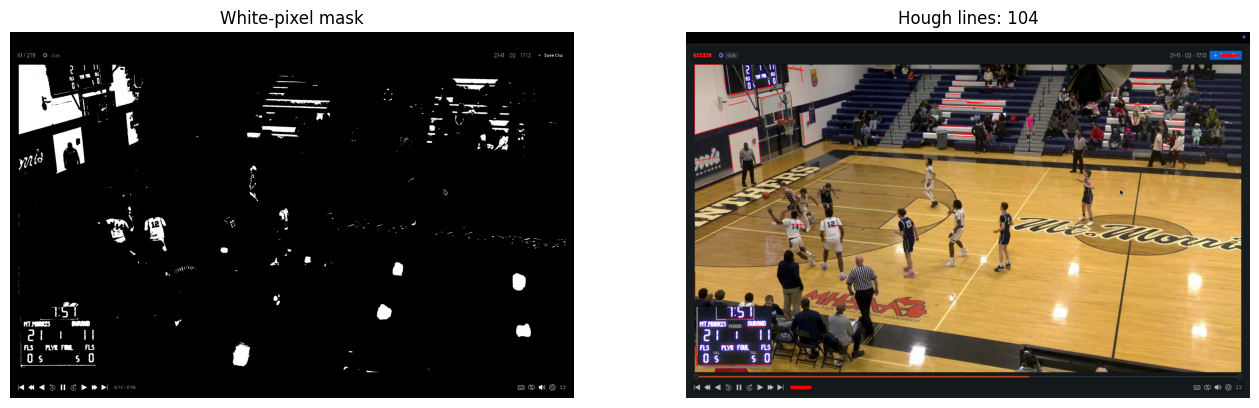

In [28]:
def opencv_lines(img_path, name=None):
    img = cv2.imread(img_path)
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    mask = cv2.inRange(hsv, (0, 0, 170), (180, 60, 255))            # bright/white pixels
    edges = cv2.Canny(cv2.GaussianBlur(mask, (5, 5), 0), 50, 150)
    lines = cv2.HoughLinesP(edges, 1, np.pi/180, 80, minLineLength=60, maxLineGap=15)
    out = img.copy()
    for x1, y1, x2, y2 in (lines[:, 0] if lines is not None else []):
        cv2.line(out, (x1, y1), (x2, y2), (0, 0, 255), 2)
    fig, ax = plt.subplots(1, 2, figsize=(16, 5))
    ax[0].imshow(mask, cmap='gray'); ax[0].set_title('White-pixel mask')
    ax[1].imshow(cv2.cvtColor(out, cv2.COLOR_BGR2RGB)); ax[1].set_title(f'Hough lines: {0 if lines is None else len(lines)}')
    for a in ax: a.axis('off')
    if name: plt.savefig(f'{FIG_DIR}/{name}.png', bbox_inches='tight')
    plt.show()

opencv_lines(TEST_IMGS[0], name='opencv_lines')

In [27]:
print(USE_IDS)
print(COURT_FT[8], COURT_FT[9])

[3, 4, 5, 6, 7, 8, 9, 10, 11]
(9.06308364868164, 16.823619842529297) (24.453044891357422, 25.223867416381836)
